In [2]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [3]:
import seaborn as sns
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
btc = yf.Ticker('BTC-USD')
prices1 = btc.history(period='5y')
prices1.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

eth = yf.Ticker('ETH-USD')
prices2 = eth.history(period='5y')
prices2.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

usdt = yf.Ticker('USDT-USD')
prices3 = usdt.history(period='5y')
prices3.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

bnb = yf.Ticker('BNB-USD')
prices4 = bnb.history(period='5y')
prices4.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

In [5]:
p1 = prices1.join(prices2, lsuffix = ' (BTC)', rsuffix = ' (ETH)')
p2 = prices3.join(prices4, lsuffix = ' (USDT)', rsuffix = ' (BNB)')
data = p1.join(p2, lsuffix = '_', rsuffix = '_')

In [6]:

import numpy as np
import pandas as pd
import pickle

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create original features (8 columns)
X_new = data.shift(1).copy()

X_new.columns = [
    col + "_Previous_Day"
    for col in X_new.columns
]

Y_new = data["Close (BTC)"].copy()

dataset_new = X_new.join(
    Y_new.rename("Target")
).dropna()

X_new = dataset_new.drop(columns=["Target"])
Y_new = dataset_new["Target"]

# 2. Chronological split
split_new = int(len(X_new) * 0.8)

X_train_new = X_new.iloc[:split_new].copy()
X_test_new = X_new.iloc[split_new:].copy()

y_train_new = Y_new.iloc[:split_new].copy()
y_test_new = Y_new.iloc[split_new:].copy()

# 3. Create a FRESH selector
selector_new = SelectKBest(
    score_func=f_regression,
    k=4
)

# IMPORTANT: Fit on all 8 original columns
X_train_selected_new = selector_new.fit_transform(
    X_train_new,
    y_train_new
)

X_test_selected_new = selector_new.transform(
    X_test_new
)

selected_features_new = list(
    X_new.columns[selector_new.get_support()]
)

# 4. Fit scaler on selected training data
scaler_new = MinMaxScaler()

X_train_scaled_new = scaler_new.fit_transform(
    X_train_selected_new
)

X_test_scaled_new = scaler_new.transform(
    X_test_selected_new
)

# 5. Train model
model_new = LinearRegression()

model_new.fit(
    X_train_scaled_new,
    y_train_new
)

# 6. Evaluate
predictions_new = model_new.predict(X_test_scaled_new)

print("MAE:", mean_absolute_error(y_test_new, predictions_new))
print("RMSE:", np.sqrt(mean_squared_error(y_test_new, predictions_new)))
print("R2:", r2_score(y_test_new, predictions_new))

# 7. Build correct model bundle
bundle_new = {
    "model": model_new,
    "feature_selector": selector_new,
    "scaler": scaler_new,
    "feature_columns": list(X_new.columns),
    "selected_features": selected_features_new,
    "model_name": "Linear Regression",
    "target_min": float(y_train_new.min()),
    "target_max": float(y_train_new.max())
}

# 8. Verify before saving
print("\nOriginal features:", len(bundle_new["feature_columns"]))
print("Selector expects:", selector_new.n_features_in_)
print("Selected features:", len(selected_features_new))
print("Scaler expects:", scaler_new.n_features_in_)
print("Model expects:", model_new.n_features_in_)

# 9. Save
with open("best_crypto_model.pkl", "wb") as file:
    pickle.dump(bundle_new, file)

print("\nNew model saved successfully!")


MAE: 1180.443866382936
RMSE: 1710.7359449444493
R2: 0.9691335825247922

Original features: 8
Selector expects: 8
Selected features: 4
Scaler expects: 4
Model expects: 4

New model saved successfully!


In [7]:
data.head()


,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2021-11-26 00:00:00+00:00,53569.765625,41810748221,4030.908936,26281795488,1.000367,106740129710,585.147339,4254504824
2021-11-27 00:00:00+00:00,54815.078125,30560857714,4096.912109,16515693874,1.001099,73666340601,600.336792,2485529516
2021-11-28 00:00:00+00:00,57248.457031,28116886357,4294.453613,15953126340,1.000125,73452340871,611.366821,2731676788
2021-11-29 00:00:00+00:00,57806.566406,32370840356,4445.104980,19086475837,1.000526,73041134842,624.310059,2425803182
2021-11-30 00:00:00+00:00,57005.425781,36708594618,4631.479004,28626354111,1.000286,87396693339,622.669861,2781531694


In [8]:
data.tail()


,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2026-11-21 00:00:00+00:00,60094.089844,58412154472,1682.204590,18933971464,0.997956,88663943646,547.511597,1362641848
2026-11-22 00:00:00+00:00,61161.910156,26196142466,1721.075684,8352233671,0.998270,46330975243,558.541504,777913583
2026-11-23 00:00:00+00:00,61210.984375,44884723836,1708.851318,16111424138,0.998788,77555827829,555.850464,1195345501
2026-11-24 00:00:00+00:00,59747.765625,32818286641,1677.694824,11272603815,0.998582,59090852604,547.740417,827907442
2026-11-26 00:00:00+00:00,60733.250000,40996454400,1693.900024,13577859072,0.998770,67442237440,558.239990,671173504


In [9]:
data.shape


(1826, 8)

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1826 entries, 2021-11-26 00:00:00+00:00 to 2026-11-26 00:00:00+00:00
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close (BTC)    1826 non-null   float64
 1   Volume (BTC)   1826 non-null   int64  
 2   Close (ETH)    1826 non-null   float64
 3   Volume (ETH)   1826 non-null   int64  
 4   Close (USDT)   1826 non-null   float64
 5   Volume (USDT)  1826 non-null   int64  
 6   Close (BNB)    1826 non-null   float64
 7   Volume (BNB)   1826 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 128.4 KB


In [11]:
data.isna().sum()


Close (BTC)      0
Volume (BTC)     0
Close (ETH)      0
Volume (ETH)     0
Close (USDT)     0
Volume (USDT)    0
Close (BNB)      0
Volume (BNB)     0
dtype: int64

In [12]:
data.describe()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
count,1826.000000,1.826000e+03,1826.000000,1.826000e+03,1826.000000,1.826000e+03,1826.000000,1.826000e+03
mean,59199.106475,3.450090e+10,2458.299210,1.742304e+10,0.999933,6.717627e+10,513.177229,1.603215e+09
std,29967.369416,2.065593e+10,836.730521,1.187642e+10,0.000681,4.218510e+10,220.769791,1.081503e+09
min,15787.284180,5.331173e+09,993.636780,2.081626e+09,0.995872,9.989859e+09,197.042999,2.038465e+08
25%,29410.323730,2.012293e+10,1805.318481,9.361724e+09,0.999612,3.913837e+10,304.741547,8.874798e+08
50%,61467.294922,2.987511e+10,2341.441528,1.463562e+10,1.000047,5.746374e+10,559.808899,1.487266e+09
75%,82578.253906,4.263719e+10,3062.624146,2.146700e+10,1.000271,8.227195e+10,648.025894,1.969047e+09
max,124752.531250,1.817464e+11,4831.348633,9.773662e+10,1.007690,3.443980e+11,1310.214355,1.182039e+10


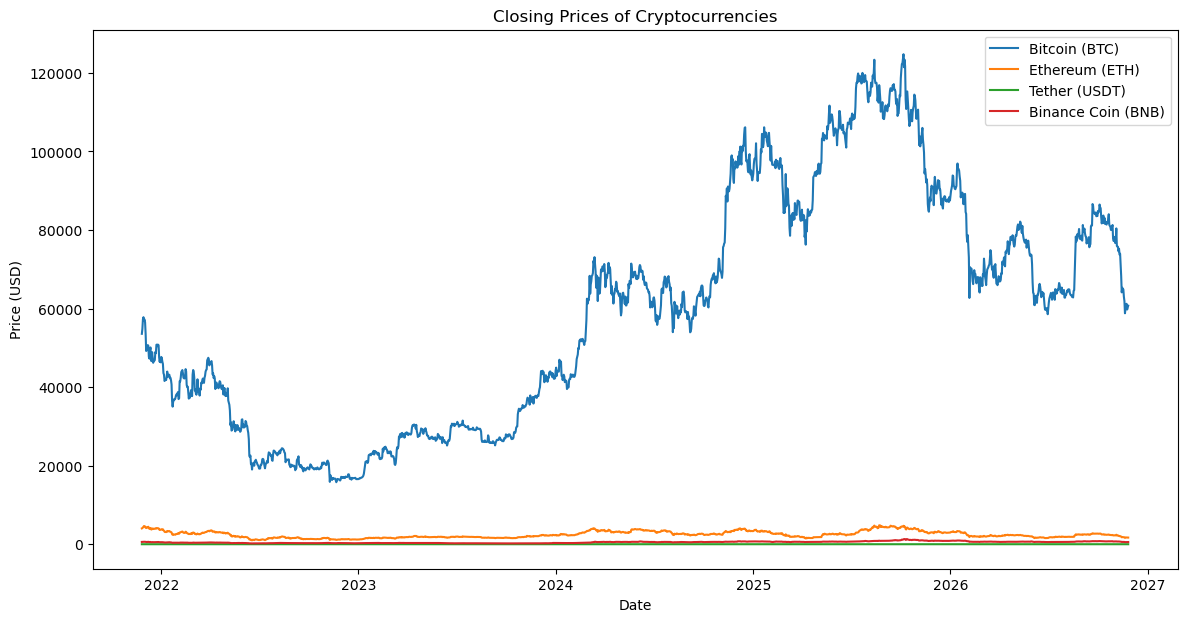

In [13]:
#Visualize the Closing Prices
# create a line plot to visualize the closing prices of all four cryptocurrencies over time:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Close (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Close (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Close (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Close (BNB)'], label='Binance Coin (BNB)')
plt.title('Closing Prices of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

<Axes: xlabel='Date'>

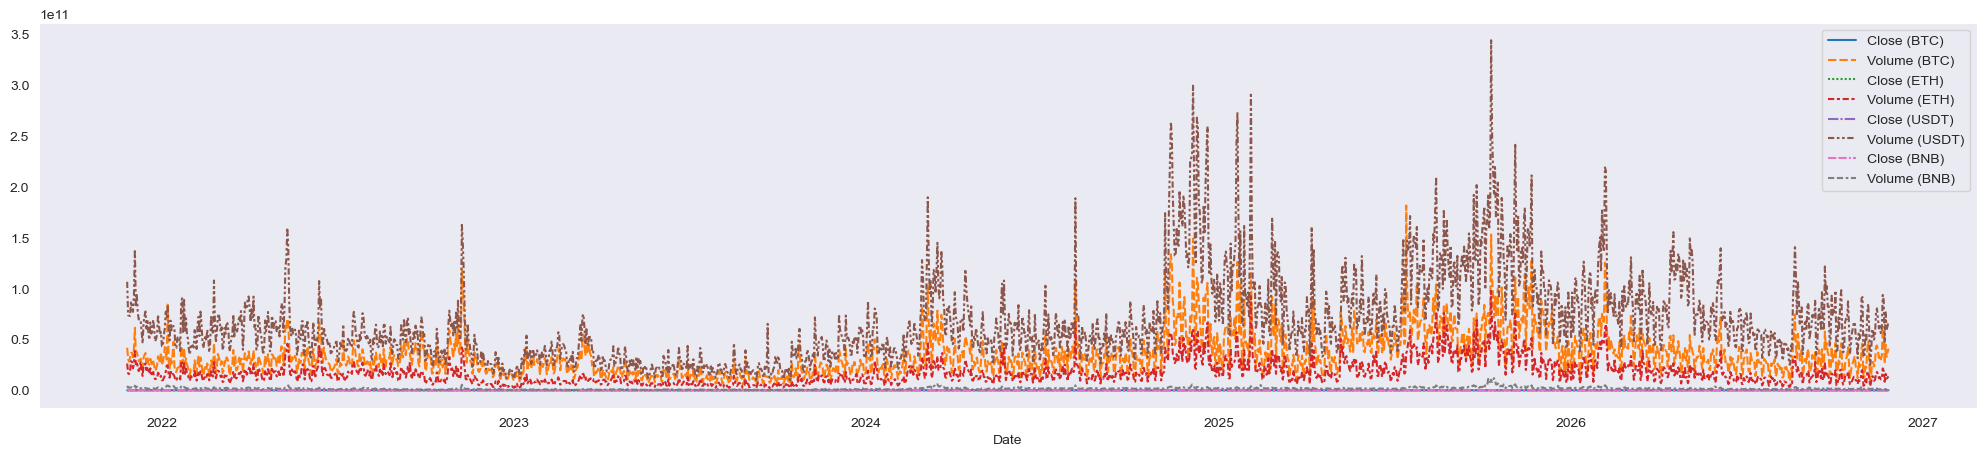

In [14]:
plt.figure(figsize = (25, 5))
sns.set_style('dark')
sns.lineplot(data=data)

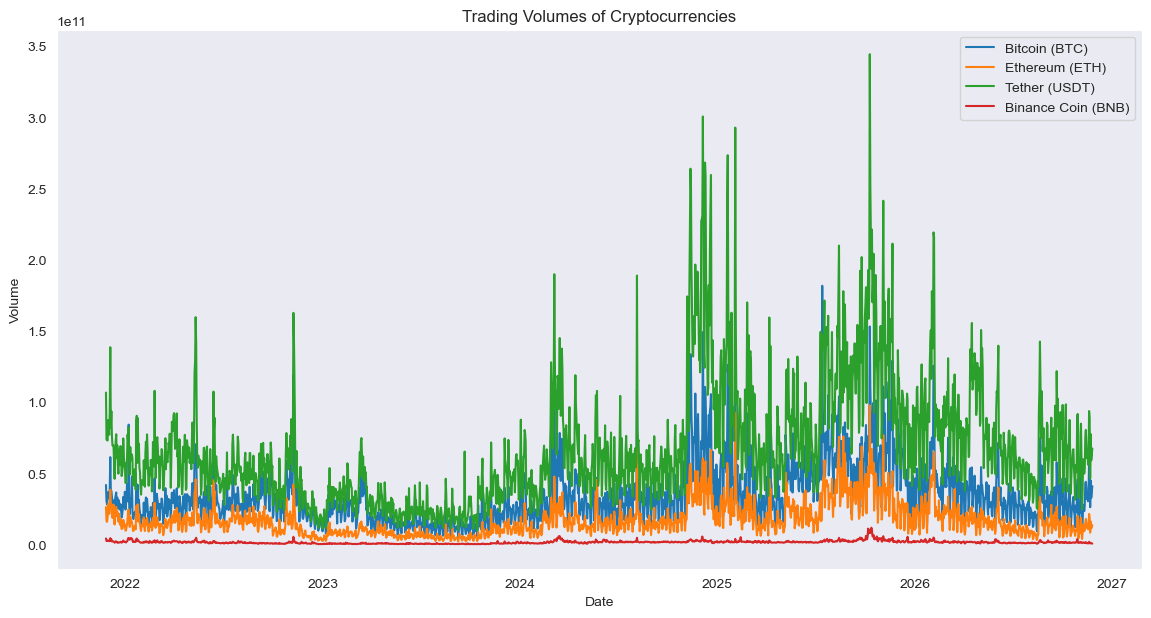

In [15]:
# Visualize the Trading Volumes
#Let's visualize the trading volumes of all four cryptocurrencies:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Volume (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Volume (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Volume (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Volume (BNB)'], label='Binance Coin (BNB)')
plt.title('Trading Volumes of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()


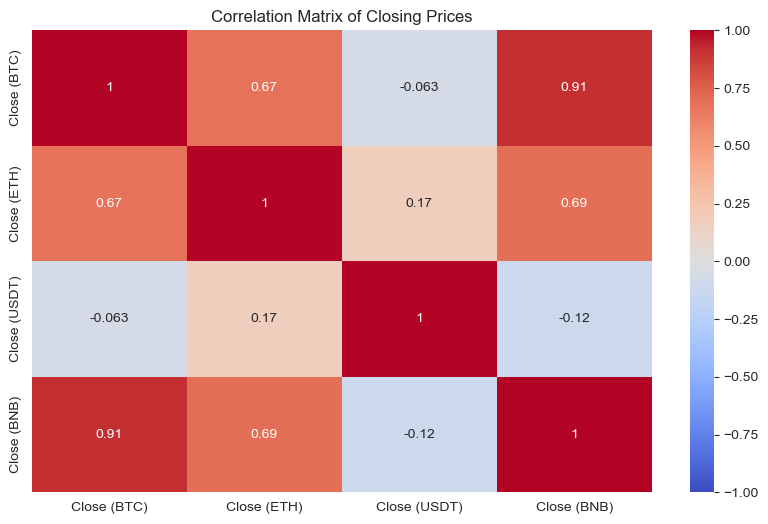

In [16]:
corr_matrix = data[
    ['Close (BTC)', 'Close (ETH)',
     'Close (USDT)', 'Close (BNB)']
].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Closing Prices')
plt.show()

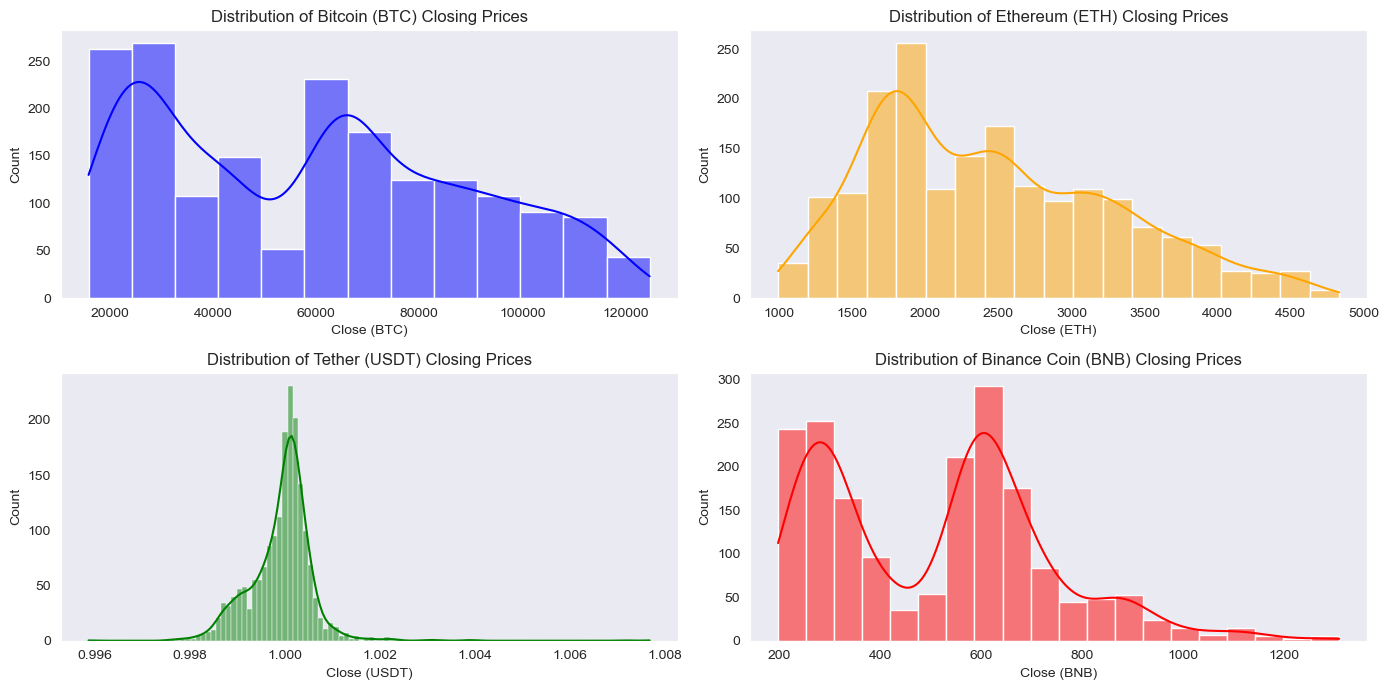

In [17]:
# Distribution of Closing Prices
#Let's plot the distribution of closing prices for each cryptocurrency:
plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
sns.histplot(data['Close (BTC)'], kde=True, color='blue')
plt.title('Distribution of Bitcoin (BTC) Closing Prices')

plt.subplot(2, 2, 2)
sns.histplot(data['Close (ETH)'], kde=True, color='orange')
plt.title('Distribution of Ethereum (ETH) Closing Prices')

plt.subplot(2, 2, 3)
sns.histplot(data['Close (USDT)'], kde=True, color='green')
plt.title('Distribution of Tether (USDT) Closing Prices')

plt.subplot(2, 2, 4)
sns.histplot(data['Close (BNB)'], kde=True, color='red')
plt.title('Distribution of Binance Coin (BNB) Closing Prices')

plt.tight_layout()
plt.show()


array([[<Axes: title={'center': 'Close (BTC)'}>,
        <Axes: title={'center': 'Volume (BTC)'}>,
        <Axes: title={'center': 'Close (ETH)'}>,
        <Axes: title={'center': 'Volume (ETH)'}>],
       [<Axes: title={'center': 'Close (USDT)'}>,
        <Axes: title={'center': 'Volume (USDT)'}>,
        <Axes: title={'center': 'Close (BNB)'}>,
        <Axes: title={'center': 'Volume (BNB)'}>]], dtype=object)

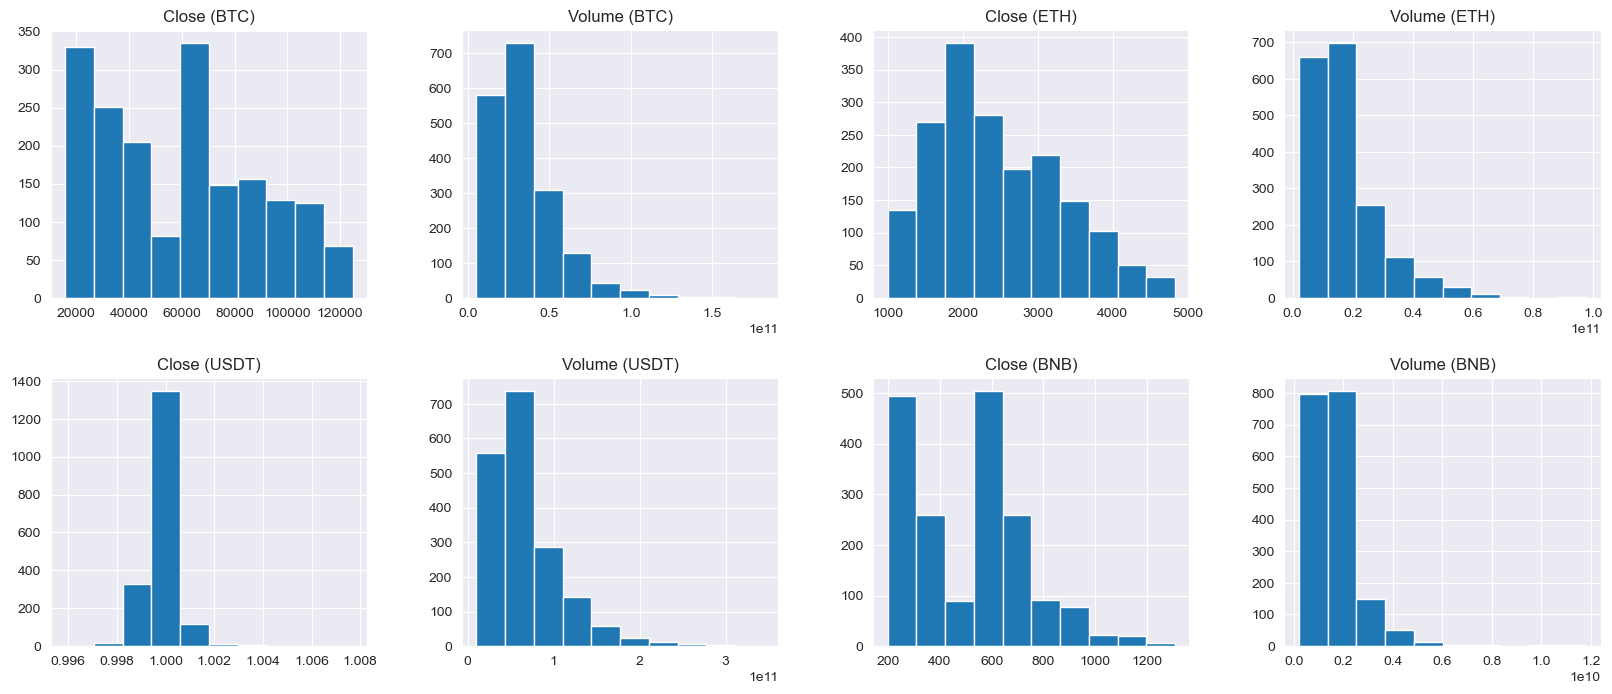

In [18]:
data.hist(figsize=(20, 8), layout=(2, 4))

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

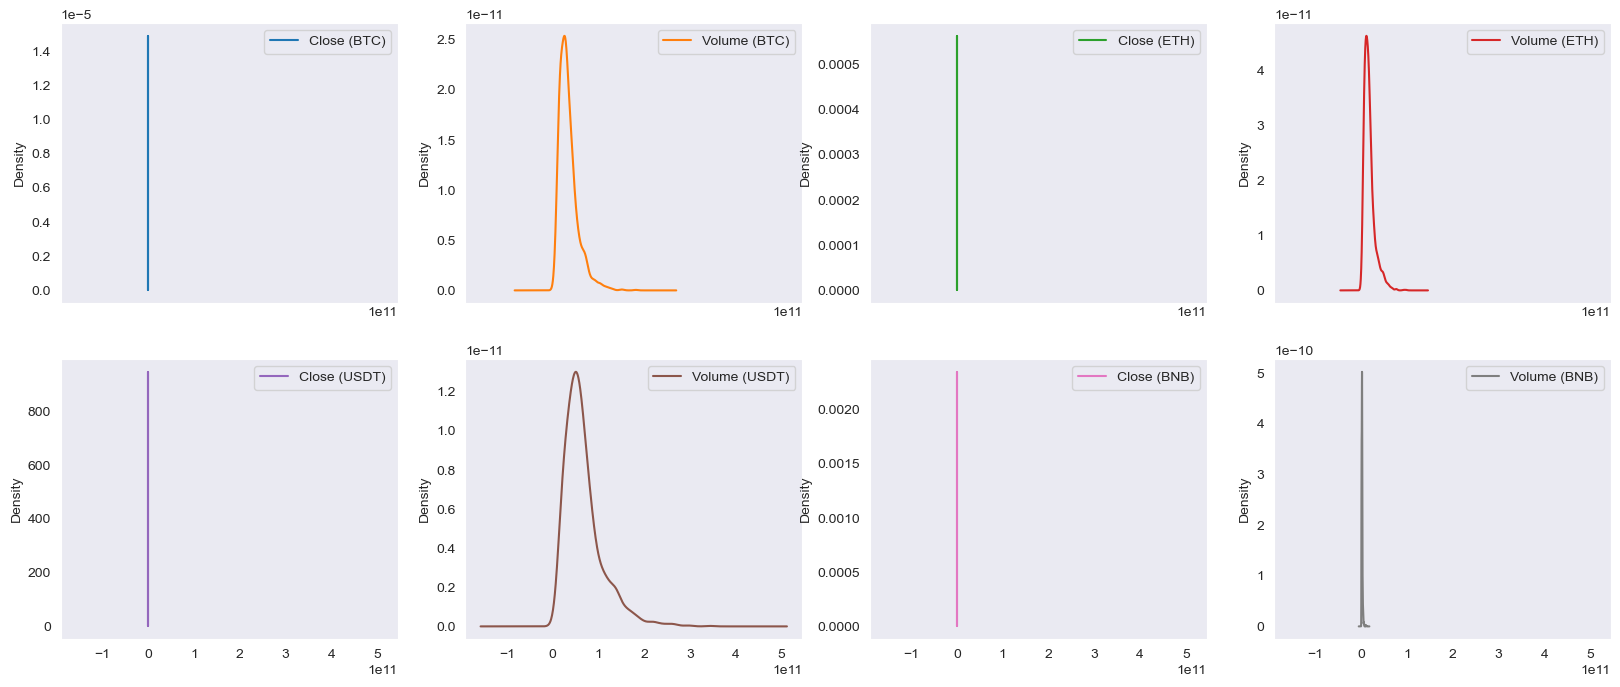

In [19]:
data.plot(kind = "kde", subplots = True, layout = (2, 4), figsize = (20, 8))

In [20]:
Q1 = data.quantile(0.25)

Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

outliers = (
    (data < lower_bound) |
    (data > upper_bound)
).sum()

print(outliers)

Close (BTC)        0
Volume (BTC)      80
Close (ETH)        0
Volume (ETH)     115
Close (USDT)      83
Volume (USDT)     94
Close (BNB)        9
Volume (BNB)      86
dtype: int64


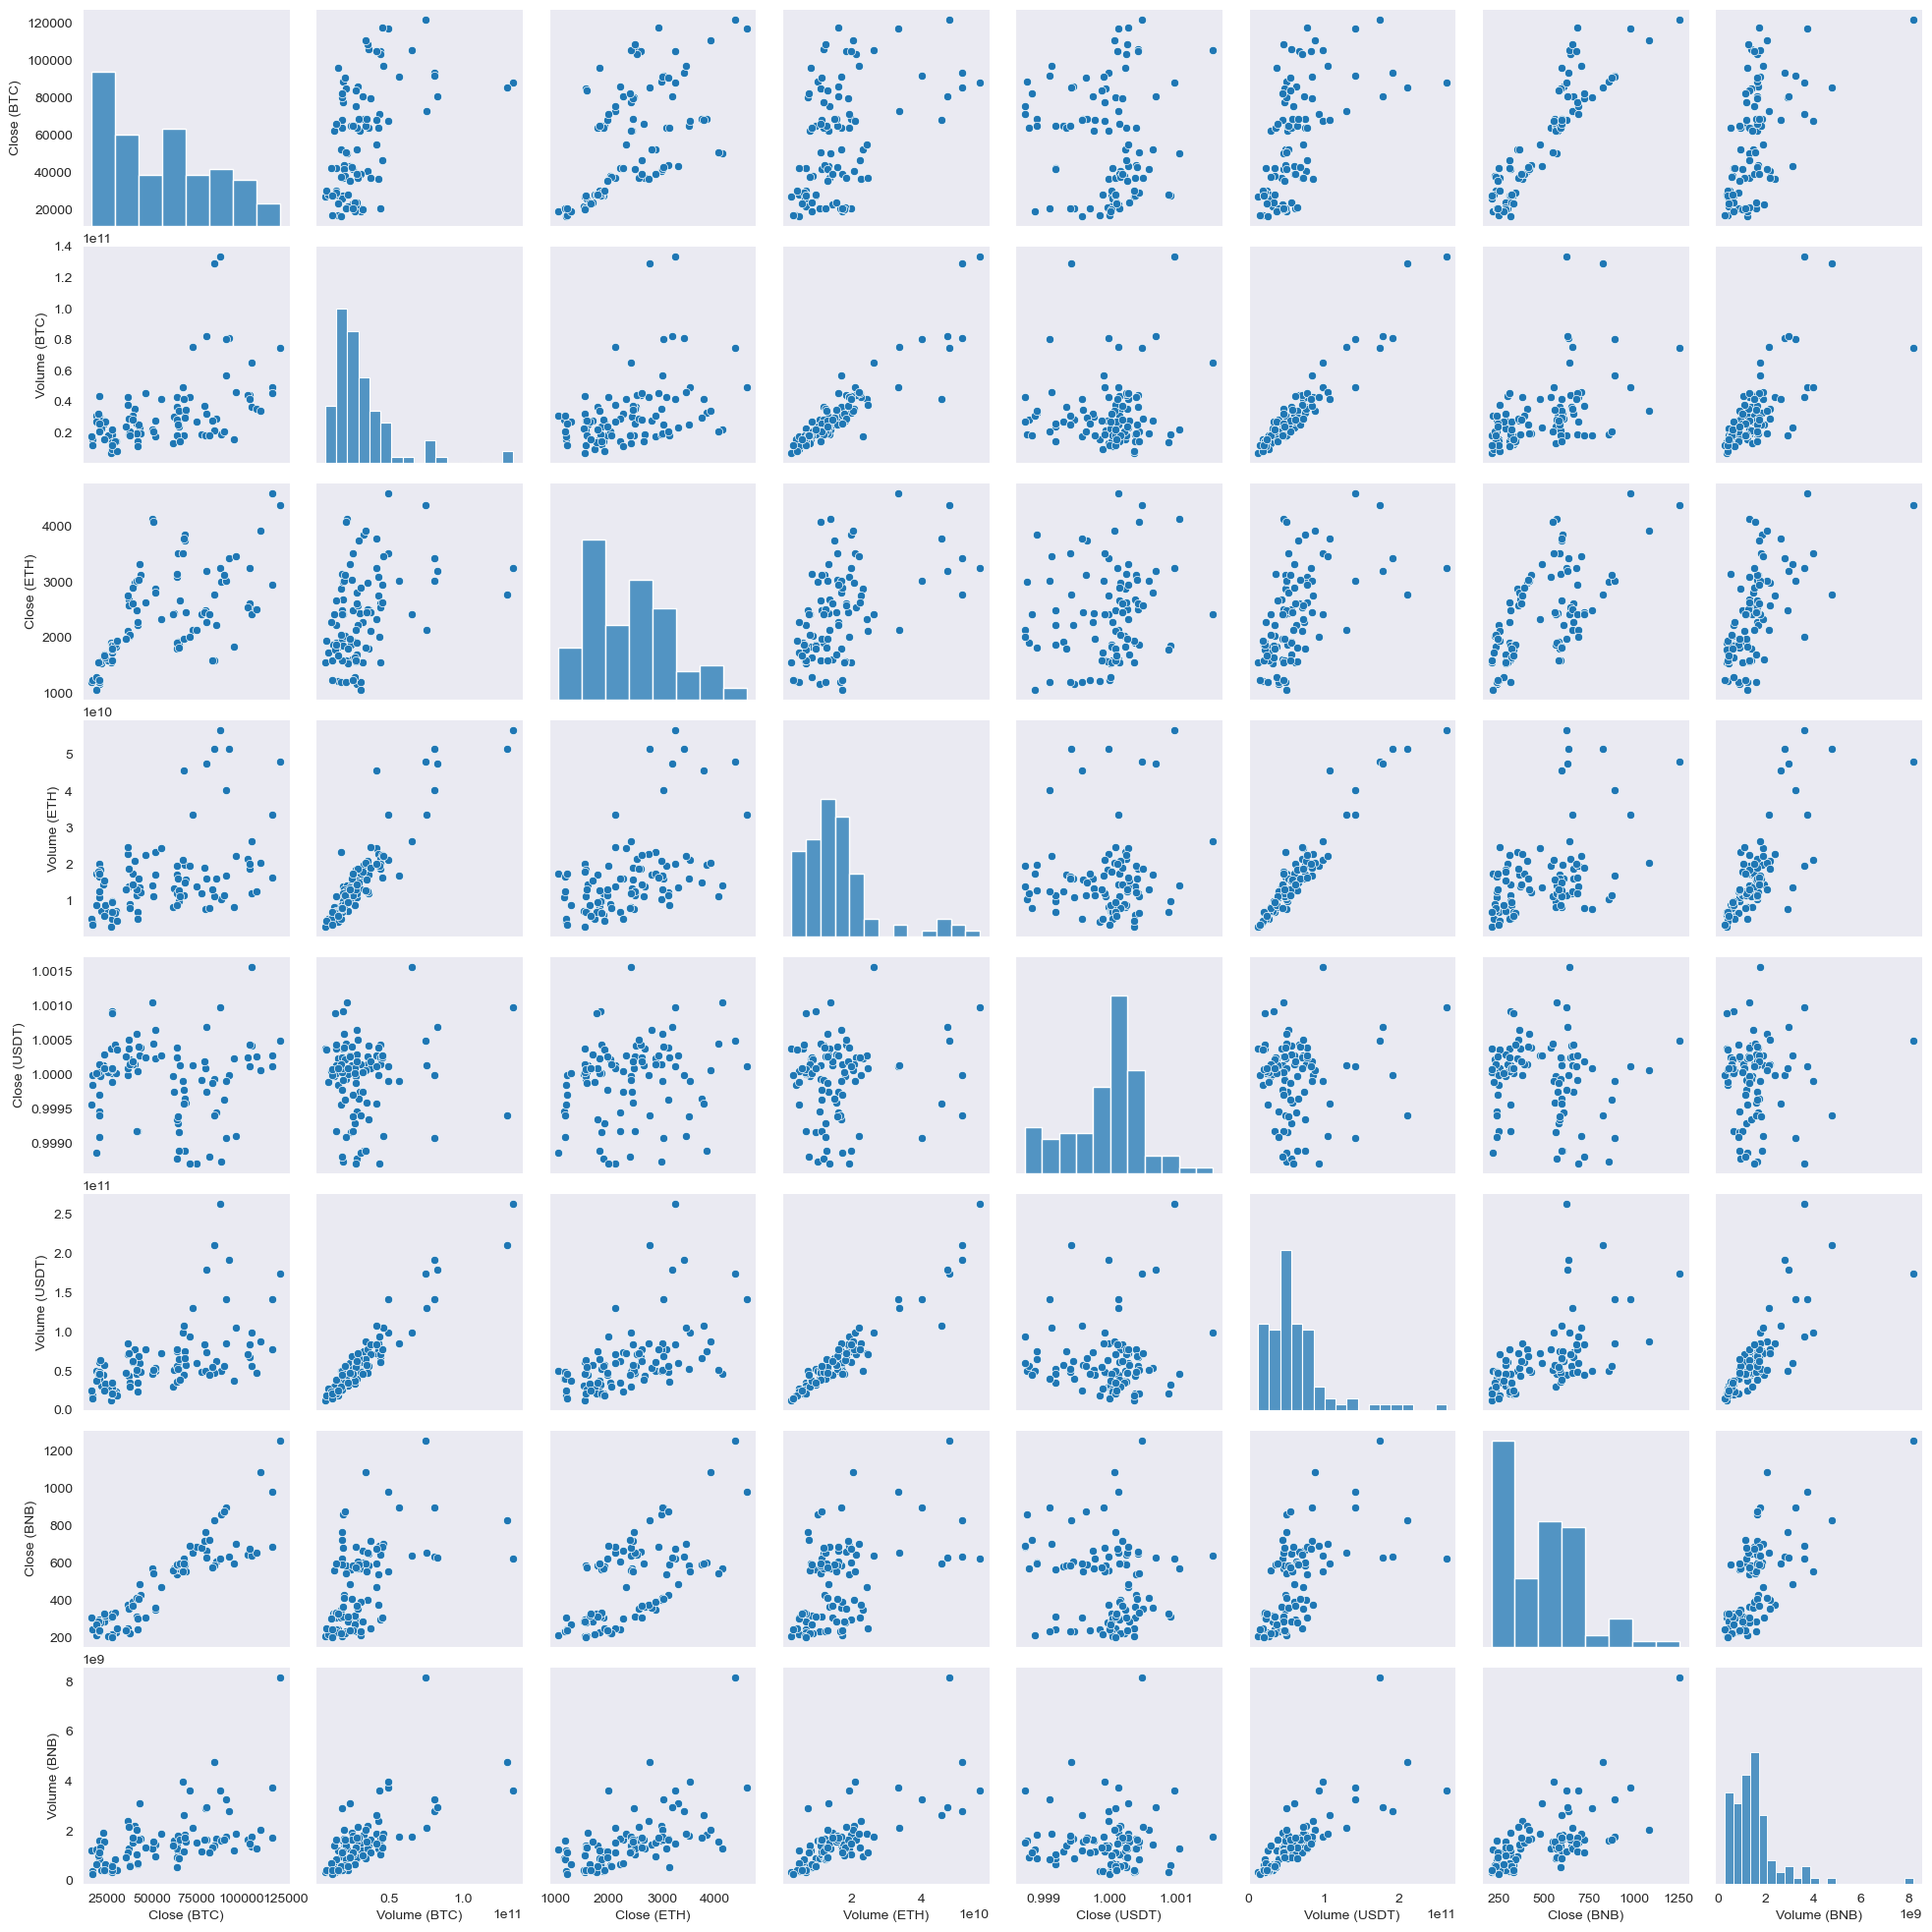

In [21]:
sns.pairplot(data.sample(n=100));

In [22]:
X = data.drop(columns = ['Close (BTC)'], axis = 1)
Y = data.loc[:, 'Close (BTC)']

In [23]:
X.head()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2021-11-26 00:00:00+00:00,41810748221,4030.908936,26281795488,1.000367,106740129710,585.147339,4254504824
2021-11-27 00:00:00+00:00,30560857714,4096.912109,16515693874,1.001099,73666340601,600.336792,2485529516
2021-11-28 00:00:00+00:00,28116886357,4294.453613,15953126340,1.000125,73452340871,611.366821,2731676788
2021-11-29 00:00:00+00:00,32370840356,4445.104980,19086475837,1.000526,73041134842,624.310059,2425803182
2021-11-30 00:00:00+00:00,36708594618,4631.479004,28626354111,1.000286,87396693339,622.669861,2781531694


In [24]:
X.tail()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2026-11-21 00:00:00+00:00,58412154472,1682.204590,18933971464,0.997956,88663943646,547.511597,1362641848
2026-11-22 00:00:00+00:00,26196142466,1721.075684,8352233671,0.998270,46330975243,558.541504,777913583
2026-11-23 00:00:00+00:00,44884723836,1708.851318,16111424138,0.998788,77555827829,555.850464,1195345501
2026-11-24 00:00:00+00:00,32818286641,1677.694824,11272603815,0.998582,59090852604,547.740417,827907442
2026-11-26 00:00:00+00:00,40996454400,1693.900024,13577859072,0.998770,67442237440,558.239990,671173504


In [25]:
Y.head()

Date
2021-11-26 00:00:00+00:00    53569.765625
2021-11-27 00:00:00+00:00    54815.078125
2021-11-28 00:00:00+00:00    57248.457031
2021-11-29 00:00:00+00:00    57806.566406
2021-11-30 00:00:00+00:00    57005.425781
Name: Close (BTC), dtype: float64

In [26]:
# Create previous-day features
X = data.shift(1).copy()

# Rename columns
X.columns = [
    col + "_Previous_Day"
    for col in X.columns
]

# Store original feature names
feature_columns = list(X.columns)

# Target
Y = data["Close (BTC)"].copy()

# Combine and remove missing values
dataset = X.join(Y.rename("Target"))
dataset.dropna(inplace=True)

X = dataset[feature_columns]
Y = dataset["Target"]

print("Feature columns:")
print(feature_columns)

Feature columns:
['Close (BTC)_Previous_Day', 'Volume (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (ETH)_Previous_Day', 'Close (USDT)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day', 'Volume (BNB)_Previous_Day']


In [27]:
import numpy as np
import pandas as pd
import pickle

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. CREATE RAW FEATURES AND TARGET
# ==========================================

X_raw = data.shift(1).copy()

X_raw.columns = [
    column + "_Previous_Day"
    for column in X_raw.columns
]

Y_raw = data["Close (BTC)"].copy()

dataset = X_raw.join(Y_raw.rename("Target")).dropna()

X_raw = dataset.drop(columns=["Target"])
Y_raw = dataset["Target"]

feature_columns = list(X_raw.columns)

# ==========================================
# 2. CHRONOLOGICAL TRAIN-TEST SPLIT
# ==========================================

split = int(len(X_raw) * 0.8)

X_train_raw = X_raw.iloc[:split].copy()
X_test_raw = X_raw.iloc[split:].copy()

Y_train = Y_raw.iloc[:split].copy()
Y_test = Y_raw.iloc[split:].copy()

# ==========================================
# 3. FEATURE SELECTION
# ==========================================

fs = SelectKBest(
    score_func=f_regression,
    k=4
)

X_train_selected = fs.fit_transform(
    X_train_raw,
    Y_train
)

X_test_selected = fs.transform(
    X_test_raw
)

selected_features = list(
    X_raw.columns[fs.get_support()]
)

print("Selected Features:")
print(selected_features)

# ==========================================
# 4. SCALING - ONLY ONCE
# ==========================================

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(
    X_train_selected
)

X_test_scaled = scaler.transform(
    X_test_selected
)

print("\nScaler minimum:")
print(scaler.data_min_)

print("\nScaler maximum:")
print(scaler.data_max_)

# ==========================================
# 5. TRAIN LINEAR REGRESSION
# ==========================================

best_model = LinearRegression()

best_model.fit(
    X_train_scaled,
    Y_train
)

# ==========================================
# 6. EVALUATION
# ==========================================

Y_pred = best_model.predict(X_test_scaled)

mae = mean_absolute_error(Y_test, Y_pred)

mse = mean_squared_error(Y_test, Y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(Y_test, Y_pred)

print("\nMODEL PERFORMANCE")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

# ==========================================
# 7. SAVE MODEL BUNDLE
# ==========================================

best_model_name = "Linear Regression"

best_model_bundle = {
    "model": best_model,
    "feature_selector": fs,
    "scaler": scaler,
    "feature_columns": feature_columns,
    "selected_features": selected_features,
    "model_name": best_model_name,
    "target_min": float(Y_train.min()),
    "target_max": float(Y_train.max())
}

with open("best_crypto_model.pkl", "wb") as file:

    pickle.dump(
        best_model_bundle,
        file
    )

print("\nModel saved successfully!")

Selected Features:
['Close (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day']

Scaler minimum:
[1.57872842e+04 9.93636780e+02 9.98985922e+09 1.97042999e+02]

Scaler maximum:
[1.24752531e+05 4.83134863e+03 3.44398037e+11 1.31021436e+03]

MODEL PERFORMANCE
MAE: 1180.443866382936
MSE: 2926617.473324978
RMSE: 1710.7359449444493
R2 Score: 0.9691335825247922

Model saved successfully!


In [28]:
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [29]:
# Print the shapes of the resulting datasets
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {Y_train.shape}')
print(f'y_test shape: {Y_test.shape}')

X_train shape: (1460, 8)
X_test shape: (365, 8)
y_train shape: (1460,)
y_test shape: (365,)


In [30]:

#Parameters
#k: Specifies the number of top features to select. In your case, k=4 indicates that you want to select the top 4 features

from sklearn.feature_selection import SelectKBest

fs = SelectKBest(k=4)
X_train = fs.fit_transform(X_train, Y_train)
X_test = fs.transform(X_test)

c:\Users\ybali\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:108: RuntimeWarning: invalid value encountered in divide
  msw = sswn / float(dfwn)


In [31]:
# mask = fs.get_support()
# selected_features = X.columns[mask]
# print("Selected Features:", selected_features) 

In [32]:
X_train

array([[9.99225020e-01, 3.87268693e+10, 2.25858505e+02, 1.02106631e+09],
       [1.00099397e+00, 1.60374457e+11, 6.44948486e+02, 2.39361086e+09],
       [1.00052595e+00, 4.67960070e+10, 5.59818848e+02, 1.72171662e+09],
       ...,
       [9.99530017e-01, 6.76936693e+10, 5.74510803e+02, 1.41874573e+09],
       [1.00031102e+00, 1.81837598e+10, 2.62148499e+02, 5.62863852e+08],
       [9.99751985e-01, 1.99456984e+10, 2.06533417e+02, 3.23117665e+08]])

In [33]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [34]:

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

----- Linear Regression -----
Mean Squared Error (MSE): 130979723.06223485
R-squared: 0.8560926372488651

----- Ridge Regression -----
Mean Squared Error (MSE): 133428767.9238415
R-squared: 0.8534018727621698

----- Lasso Regression -----
Mean Squared Error (MSE): 131008290.56917135
R-squared: 0.8560612501418572

----- ElasticNet Regression -----
Mean Squared Error (MSE): 780523576.1054746
R-squared: 0.14243909838583613

----- Support Vector Regression (SVR) -----
Mean Squared Error (MSE): 907378327.9929898
R-squared: 0.00306383960698009

----- Decision Tree Regression -----
Mean Squared Error (MSE): 95356036.65450552
R-squared: 0.8952323654644601

----- Random Forest Regression -----
Mean Squared Error (MSE): 58715508.79628478
R-squared: 0.9354892969238483

----- Gradient Boosting Regression -----
Mean Squared Error (MSE): 63754693.02131962
R-squared: 0.9299527474848385

----- K-Nearest Neighbors Regression -----
Mean Squared Error (MSE): 61908021.1510779
R-squared: 0.9319816850371565

c:\Users\ybali\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


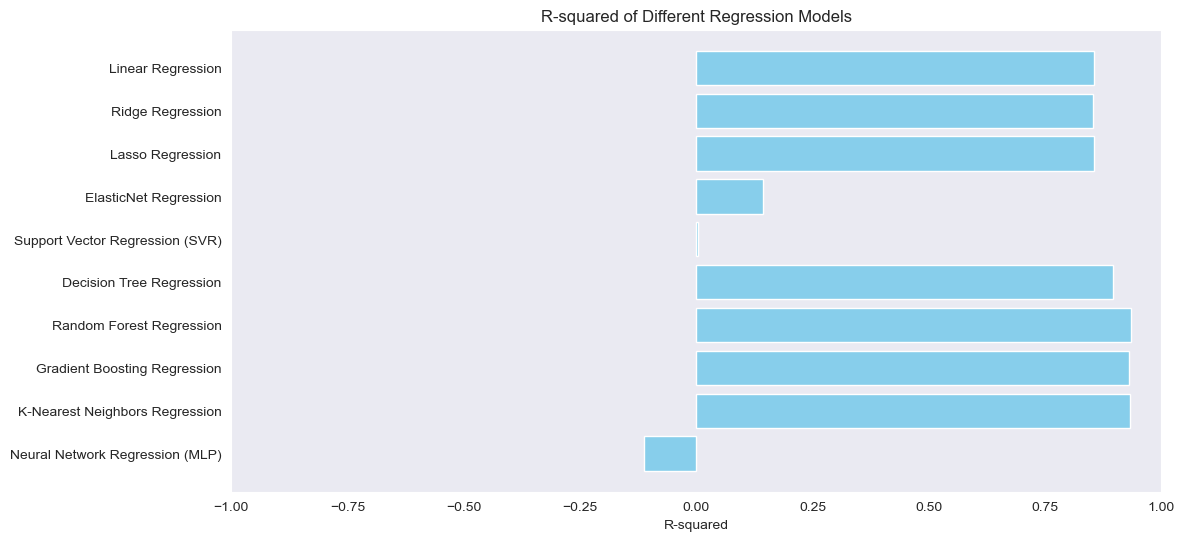

In [35]:

#Define Models and Perform Training and Evaluation
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'ElasticNet Regression': ElasticNet(alpha=1.0, l1_ratio=0.5),
    'Support Vector Regression (SVR)': SVR(kernel='rbf'),
    'Decision Tree Regression': DecisionTreeRegressor(),
    'Random Forest Regression': RandomForestRegressor(n_estimators=100),
    'Gradient Boosting Regression': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1),
    'K-Nearest Neighbors Regression': KNeighborsRegressor(n_neighbors=5),
    'Neural Network Regression (MLP)': MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam')
}

# Train and evaluate each model
results = {'Model': [], 'MSE': [], 'R-squared': []}

for name, model in models.items():
    # Train the model
    model.fit(X_train, Y_train)

    # Predict on test set
    Y_pred = model.predict(X_test)

    # Evaluate model
    mse = mean_squared_error(Y_test, Y_pred)
    r2 = r2_score(Y_test, Y_pred)

    # Store results
    results['Model'].append(name)
    results['MSE'].append(mse)
    results['R-squared'].append(r2)

    # Print results
    print(f"----- {name} -----")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared: {r2}")
    print()

# Convert results to DataFrame for visualization
results_df = pd.DataFrame(results)
print(results_df)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.barh(results_df['Model'], results_df['R-squared'], color='skyblue')
plt.xlabel('R-squared')
plt.title('R-squared of Different Regression Models')
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.show()

In [36]:
# Select the best model based on lowest RMSE
# Select the best model based on lowest RMSE

best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best Model Object:", best_model)

Best Model: Linear Regression
Best Model Object: LinearRegression()


In [37]:
import pickle
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
X, Y = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=0)


# Scale the features (optional but recommended for some algorithms)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)

# Train the model
model_rf.fit(X_train, Y_train)

# Save the model to a file
filename = 'random_forest_model.pkl'
pickle.dump(model_rf, open(filename, 'wb'))

# Save scaler to a file
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Load the model from the file
loaded_model = pickle.load(open(filename, 'rb'))

# Predict using the loaded model
Y_pred = loaded_model.predict(X_test)

# Evaluate the loaded model
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"Loaded Random Forest Regression - Mean Squared Error (MSE): {mse}")
print(f"Loaded Random Forest Regression - R-squared: {r2}")


Loaded Random Forest Regression - Mean Squared Error (MSE): 58446465.40368198
Loaded Random Forest Regression - R-squared: 0.9357848947781566


In [38]:
import os

print("File exists:", os.path.exists("best_crypto_model.pkl"))

if os.path.exists("best_crypto_model.pkl"):
    print("File size:", os.path.getsize("best_crypto_model.pkl"), "bytes")

File exists: True
File size: 1779 bytes


In [39]:
import os

file_path = "best_crypto_model.pkl"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
    print("File location:", os.path.abspath(file_path))

File exists: True
File size: 1779 bytes
File location: c:\Users\ybali\MACHINE LEARNING PROJECTS\Crypto-Price-Prediction\best_crypto_model.pkl


In [40]:
import os

print("File location:", os.path.abspath("best_crypto_model.pkl"))
print("File size:", os.path.getsize("best_crypto_model.pkl"), "bytes")

File location: c:\Users\ybali\MACHINE LEARNING PROJECTS\Crypto-Price-Prediction\best_crypto_model.pkl
File size: 1779 bytes


In [41]:
import pickle

best_model_bundle = {
    "model": best_model,
    "feature_selector": fs,
    "scaler": scaler,
    "selected_features": list(selected_features),
    "model_name": best_model_name
}

with open("best_crypto_model.pkl", "wb") as file:
    pickle.dump(best_model_bundle, file)

print("Model saved successfully!")

Model saved successfully!


In [42]:
with open("best_crypto_model.pkl", "rb") as file:
    bundle = pickle.load(file)

print("Model:", bundle["model_name"])

Model: Linear Regression


In [43]:
import pickle

with open("best_crypto_model.pkl", "rb") as file:
    bundle = pickle.load(file)

print(bundle.keys())


dict_keys(['model', 'feature_selector', 'scaler', 'selected_features', 'model_name'])


In [44]:
X_original = data.shift(1).copy()

X_original.columns = [
    col + "_Previous_Day"
    for col in X_original.columns
]

X_original = X_original.loc[data.index]

feature_columns = list(X_original.columns)

print(feature_columns)

['Close (BTC)_Previous_Day', 'Volume (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (ETH)_Previous_Day', 'Close (USDT)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day', 'Volume (BNB)_Previous_Day']


In [45]:
best_model_bundle = {
    "model": best_model,
    "feature_selector": fs,
    "scaler": scaler,
    "feature_columns": feature_columns,
    "selected_features": list(selected_features),
    "model_name": best_model_name
}

with open("best_crypto_model.pkl", "wb") as file:
    pickle.dump(best_model_bundle, file)

print("Complete model saved successfully!")

Complete model saved successfully!


In [46]:
print("Original features:",
      len(best_model_bundle["feature_columns"]))

print("Selector expects:",
      best_model_bundle["feature_selector"].n_features_in_)

print("Selected features:",
      len(best_model_bundle["selected_features"]))

print("Scaler expects:",
      best_model_bundle["scaler"].n_features_in_)

print("Model expects:",
      best_model_bundle["model"].n_features_in_)

Original features: 8
Selector expects: 8
Selected features: 4
Scaler expects: 4
Model expects: 4


In [47]:
with open("best_crypto_model.pkl", "rb") as file:
    bundle = pickle.load(file)

print(bundle.keys())
print("Best Model:", bundle["model_name"])
print("Features:", bundle["feature_columns"])

dict_keys(['model', 'feature_selector', 'scaler', 'feature_columns', 'selected_features', 'model_name'])
Best Model: Linear Regression
Features: ['Close (BTC)_Previous_Day', 'Volume (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (ETH)_Previous_Day', 'Close (USDT)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day', 'Volume (BNB)_Previous_Day']


In [48]:
import pickle
import os

print("File location:", os.path.abspath("best_crypto_model.pkl"))

with open("best_crypto_model.pkl", "rb") as file:
    bundle = pickle.load(file)

print("Available keys:", bundle.keys())
print("Model:", bundle.get("model_name"))

File location: c:\Users\ybali\MACHINE LEARNING PROJECTS\Crypto-Price-Prediction\best_crypto_model.pkl
Available keys: dict_keys(['model', 'feature_selector', 'scaler', 'feature_columns', 'selected_features', 'model_name'])
Model: Linear Regression


In [49]:
print("Y_train minimum:", Y_train.min())
print("Y_train maximum:", Y_train.max())

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("Selected features:", selected_features)

print("Best model:", best_model_name)

Y_train minimum: 15787.2841796875
Y_train maximum: 123513.4765625
X_train shape: (1460, 4)
X_test shape: (365, 4)
Selected features: ['Close (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day']
Best model: Linear Regression


In [50]:
print("Prediction:", best_model.predict(X_test[:1]))
print("Minimum training BTC price:", Y_train.min())
print("Maximum training BTC price:", Y_train.max())

Prediction: [32462.10065769]
Minimum training BTC price: 15787.2841796875
Maximum training BTC price: 123513.4765625


In [51]:
print("Best Model:", best_model_name)

print("Minimum BTC price:", Y_train.min())

print("Maximum BTC price:", Y_train.max())

print("Selected Features:", selected_features)

Best Model: Linear Regression
Minimum BTC price: 15787.2841796875
Maximum BTC price: 123513.4765625
Selected Features: ['Close (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day']


In [52]:
print("FEATURES USED BY MODEL:")
print(selected_features)

print("\nSCALER MINIMUM:")
print(scaler.data_min_)

print("\nSCALER MAXIMUM:")
print(scaler.data_max_)

print("\nMODEL COEFFICIENTS:")
print(best_model.coef_)

print("\nMODEL INTERCEPT:")
print(best_model.intercept_)

FEATURES USED BY MODEL:
['Close (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day']

SCALER MINIMUM:
[0. 0. 0. 0.]

SCALER MAXIMUM:
[1. 1. 1. 1.]

MODEL COEFFICIENTS:
[ 22043.03360283  57067.80753142 134432.98801287 -69945.38422352]

MODEL INTERCEPT:
12800.046299009606


In [53]:
print("BEST MODEL:")
print(best_model_name)

print("\nSELECTED FEATURES:")
print(selected_features)

print("\nSCALER MINIMUM:")
print(scaler.data_min_)

print("\nSCALER MAXIMUM:")
print(scaler.data_max_)

print("\nMODEL COEFFICIENTS:")
print(best_model.coef_)

print("\nMODEL INTERCEPT:")
print(best_model.intercept_)

print("\nTRAINING TARGET MINIMUM:")
print(Y_train.min())

print("\nTRAINING TARGET MAXIMUM:")
print(Y_train.max())

BEST MODEL:
Linear Regression

SELECTED FEATURES:
['Close (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day']

SCALER MINIMUM:
[0. 0. 0. 0.]

SCALER MAXIMUM:
[1. 1. 1. 1.]

MODEL COEFFICIENTS:
[ 22043.03360283  57067.80753142 134432.98801287 -69945.38422352]

MODEL INTERCEPT:
12800.046299009606

TRAINING TARGET MINIMUM:
15787.2841796875

TRAINING TARGET MAXIMUM:
123513.4765625


In [54]:
print(scaler.data_min_)
print(scaler.data_max_)

[0. 0. 0. 0.]
[1. 1. 1. 1.]


In [55]:
print("Feature columns:", len(best_model_bundle["feature_columns"]))

print("Selector expects:",
      best_model_bundle["feature_selector"].n_features_in_)

print("Selected features:",
      best_model_bundle["selected_features"])

print("Scaler expects:",
      best_model_bundle["scaler"].n_features_in_)

print("Model expects:",
      best_model_bundle["model"].n_features_in_)

Feature columns: 8
Selector expects: 8
Selected features: ['Close (BTC)_Previous_Day', 'Close (ETH)_Previous_Day', 'Volume (USDT)_Previous_Day', 'Close (BNB)_Previous_Day']
Scaler expects: 4
Model expects: 4


In [56]:
import pickle
import os

model_path = os.path.abspath("best_crypto_model.pkl")

with open(model_path, "wb") as file:
    pickle.dump(best_model_bundle, file)

print("Saved model at:", model_path)

Saved model at: c:\Users\ybali\MACHINE LEARNING PROJECTS\Crypto-Price-Prediction\best_crypto_model.pkl


In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: predict tomorrow's BTC price
# using yesterday's BTC closing price

baseline_predictions = X_test_raw[
    "Close (BTC)_Previous_Day"
].values

# Linear Regression predictions
model_predictions = predictions_new

# Compare performance
models_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test_new, baseline_predictions),
        mean_absolute_error(y_test_new, model_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_new, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test_new, model_predictions))
    ],
    "R2 Score": [
        r2_score(y_test_new, baseline_predictions),
        r2_score(y_test_new, model_predictions)
    ]
})

print(models_comparison)

                  Model          MAE         RMSE  R2 Score
0  Persistence Baseline  1181.796533  1715.646169  0.968956
1     Linear Regression  1180.443866  1710.735945  0.969134


In [58]:
baseline_mae = models_comparison.loc[
    models_comparison["Model"] == "Persistence Baseline",
    "MAE"
].iloc[0]

model_mae = models_comparison.loc[
    models_comparison["Model"] == "Linear Regression",
    "MAE"
].iloc[0]

improvement = (
    (baseline_mae - model_mae) / baseline_mae
) * 100

print(f"MAE Improvement: {improvement:.4f}%")

MAE Improvement: 0.1145%


In [59]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=5)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_new), start=1):

    X_train_fold = X_new.iloc[train_idx]
    X_test_fold = X_new.iloc[test_idx]

    y_train_fold = Y_new.iloc[train_idx]
    y_test_fold = Y_new.iloc[test_idx]

    # Complete preprocessing and model training in one pipeline
    pipeline = Pipeline([
        ("selector", SelectKBest(f_regression, k=4)),
        ("scaler", MinMaxScaler()),
        ("model", LinearRegression())
    ])

    pipeline.fit(X_train_fold, y_train_fold)

    predictions = pipeline.predict(X_test_fold)

    baseline = X_test_fold["Close (BTC)_Previous_Day"]

    model_mae = mean_absolute_error(y_test_fold, predictions)
    baseline_mae = mean_absolute_error(y_test_fold, baseline)

    fold_results.append({
        "Fold": fold,
        "Model MAE": model_mae,
        "Baseline MAE": baseline_mae
    })

cv_results = pd.DataFrame(fold_results)

print(cv_results)

print("\nAverage Model MAE:", cv_results["Model MAE"].mean())
print("Average Baseline MAE:", cv_results["Baseline MAE"].mean())

   Fold    Model MAE  Baseline MAE
0     1   399.162153    384.596680
1     2   906.211748    887.048430
2     3  1504.557498   1466.849198
3     4  1453.114623   1458.892809
4     5  1179.258500   1180.404091

Average Model MAE: 1088.4609045517786
Average Baseline MAE: 1075.5582416735197


In [60]:

# FEATURE ENGINEERING

import pandas as pd
import numpy as np

features = pd.DataFrame(index=data.index)

# BTC historical prices
features["BTC_Lag_1"] = data["Close (BTC)"].shift(1)
features["BTC_Lag_2"] = data["Close (BTC)"].shift(2)
features["BTC_Lag_3"] = data["Close (BTC)"].shift(3)
features["BTC_Lag_7"] = data["Close (BTC)"].shift(7)

# BTC moving average and volatility
features["BTC_MA_7"] = (
    data["Close (BTC)"].shift(1).rolling(7).mean()
)

features["BTC_Volatility_7"] = (
    data["Close (BTC)"].shift(1).rolling(7).std()
)

# Other cryptocurrency prices
for coin in ["ETH", "USDT", "BNB"]:

    features[f"{coin}_Close_Lag_1"] = (
        data[f"Close ({coin})"].shift(1)
    )

# Target
target = data["Close (BTC)"]

# Remove missing rows
engineered_data = features.join(
    target.rename("Target")
).dropna()

X_engineered = engineered_data.drop(columns=["Target"])
Y_engineered = engineered_data["Target"]

print("Engineered features:", X_engineered.shape)
print("Target shape:", Y_engineered.shape)

display(X_engineered.head())


Engineered features: (1819, 9)
Target shape: (1819,)


,BTC_Lag_1,BTC_Lag_2,BTC_Lag_3,BTC_Lag_7,BTC_MA_7,BTC_Volatility_7,ETH_Close_Lag_1,USDT_Close_Lag_1,BNB_Close_Lag_1
Date,,,,,,,,,
2021-12-03 00:00:00+00:00,56477.816406,57229.828125,57005.425781,53569.765625,56307.562500,1539.583818,4511.302246,1.000174,619.470154
2021-12-04 00:00:00+00:00,53598.246094,56477.816406,57229.828125,54815.078125,56311.631138,1531.157394,4220.706055,1.000617,594.635986
2021-12-05 00:00:00+00:00,49200.703125,53598.246094,56477.816406,57248.457031,55509.577567,3106.156643,4119.587402,1.000007,569.077271
2021-12-06 00:00:00+00:00,49368.847656,49200.703125,53598.246094,57806.566406,54383.919085,3735.067324,4198.322754,1.000630,557.783081
2021-12-07 00:00:00+00:00,50582.625000,49368.847656,49200.703125,57005.425781,53351.927455,3628.237461,4358.737305,1.001362,589.256165


In [61]:

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    )
}

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

results = []

for name, model in models.items():

    fold_mae = []
    fold_rmse = []
    fold_r2 = []
    baseline_mae = []

    for train_index, test_index in tscv.split(X_engineered):

        X_train = X_engineered.iloc[train_index]
        X_test = X_engineered.iloc[test_index]

        y_train = Y_engineered.iloc[train_index]
        y_test = Y_engineered.iloc[test_index]

        # Train model
        model.fit(X_train, y_train)

        # Model predictions
        predictions = model.predict(X_test)

        # Persistence baseline
        baseline_predictions = X_test["BTC_Lag_1"]

        # Evaluation
        fold_mae.append(
            mean_absolute_error(y_test, predictions)
        )

        fold_rmse.append(
            np.sqrt(mean_squared_error(y_test, predictions))
        )

        fold_r2.append(
            r2_score(y_test, predictions)
        )

        baseline_mae.append(
            mean_absolute_error(y_test, baseline_predictions)
        )

    results.append({
        "Model": name,
        "Average MAE": np.mean(fold_mae),
        "Average RMSE": np.mean(fold_rmse),
        "Average R2": np.mean(fold_r2),
        "Baseline MAE": np.mean(baseline_mae)
    })

# Results table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Average MAE"
).reset_index(drop=True)

display(results_df)


,Model,Average MAE,Average RMSE,Average R2,Baseline MAE
0,Ridge Regression,1122.568310,1592.546919,0.975260,1078.453518
1,Linear Regression,1132.969366,1599.208669,0.975185,1078.453518
2,Gradient Boosting,5903.945003,8218.138130,0.507500,1078.453518
3,Random Forest,6025.355190,8339.145739,0.499252,1078.453518


In [62]:

baseline_mae = results_df["Baseline MAE"].iloc[0]

results_df["MAE Improvement (%)"] = (
    (baseline_mae - results_df["Average MAE"])
    / baseline_mae
) * 100

display(results_df)

best_row = results_df.loc[
    results_df["Average MAE"].idxmin()
]

if best_row["Average MAE"] < baseline_mae:
    print("ML model beats the baseline!")
    print("Best model:", best_row["Model"])
else:
    print("No ML model beats the baseline yet.")
    print("We need better features or model tuning.")


,Model,Average MAE,Average RMSE,Average R2,Baseline MAE,MAE Improvement (%)
0,Ridge Regression,1122.568310,1592.546919,0.975260,1078.453518,-4.090560
1,Linear Regression,1132.969366,1599.208669,0.975185,1078.453518,-5.055002
2,Gradient Boosting,5903.945003,8218.138130,0.507500,1078.453518,-447.445477
3,Random Forest,6025.355190,8339.145739,0.499252,1078.453518,-458.703281


No ML model beats the baseline yet.
We need better features or model tuning.


In [63]:

# ==========================================
# FEATURE ENGINEERING - VERSION 2
# ==========================================

btc = data["Close (BTC)"]

X_engineered = pd.DataFrame(index=data.index)

# BTC historical prices
X_engineered["BTC_Lag_1"] = btc
X_engineered["BTC_Lag_2"] = btc.shift(1)
X_engineered["BTC_Lag_3"] = btc.shift(2)
X_engineered["BTC_Lag_7"] = btc.shift(6)

# Moving averages
X_engineered["BTC_MA_7"] = btc.rolling(7).mean()
X_engineered["BTC_MA_14"] = btc.rolling(14).mean()

# Daily returns
returns = btc.pct_change()

X_engineered["BTC_Return_1d"] = returns

# Volatility
X_engineered["BTC_Volatility_7"] = (
    returns.rolling(7).std()
)

# Other cryptocurrency information
for column in [
    "Close (ETH)",
    "Close (USDT)",
    "Close (BNB)",
    "Volume (BTC)",
    "Volume (ETH)",
    "Volume (USDT)",
    "Volume (BNB)"
]:
    X_engineered[column] = data[column]

# Predict the next day's BTC closing price
Y_engineered = btc.shift(-1).rename("BTC_Next_Day")

# Combine and remove missing values
engineered_data = X_engineered.join(Y_engineered)
engineered_data = engineered_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

X_engineered = engineered_data.drop(
    columns=["BTC_Next_Day"]
)

Y_engineered = engineered_data["BTC_Next_Day"]

print("Features shape:", X_engineered.shape)
print("Target shape:", Y_engineered.shape)

display(X_engineered.head())


Features shape: (1812, 15)
Target shape: (1812,)


,BTC_Lag_1,BTC_Lag_2,BTC_Lag_3,BTC_Lag_7,BTC_MA_7,BTC_MA_14,BTC_Return_1d,BTC_Volatility_7,Close (ETH),Close (USDT),Close (BNB),Volume (BTC),Volume (ETH),Volume (USDT),Volume (BNB)
Date,,,,,,,,,,,,,,,
2021-12-09 00:00:00+00:00,47672.121094,50504.796875,50700.085938,53598.246094,50232.489397,53270.025949,-0.056087,0.039442,4119.815918,1.000882,571.648987,29603577251,22296131874,69831553004,2132955304
2021-12-10 00:00:00+00:00,47243.304688,47672.121094,50504.796875,49200.703125,49324.640625,52818.135882,-0.008995,0.037672,3908.496094,1.001740,552.966858,30966005122,28014595631,68959994142,2089946472
2021-12-11 00:00:00+00:00,49362.507812,47243.304688,47672.121094,49368.847656,49347.755580,52428.666574,0.044857,0.031277,4084.452393,1.000556,564.322510,25775869261,19131502454,57132834419,1824951693
2021-12-12 00:00:00+00:00,50098.335938,49362.507812,47243.304688,50582.625000,49451.968192,51917.943638,0.014907,0.031730,4134.453125,1.001051,570.823975,21939223599,14057603914,46141935617,1307635490
2021-12-13 00:00:00+00:00,46737.480469,50098.335938,49362.507812,50700.085938,48902.661830,51127.294643,-0.067085,0.039160,3784.226807,1.000131,521.011597,32166727776,23999841386,66458705759,1900967743


In [64]:

import pandas as pd
import numpy as np

# Create feature DataFrame
btc = data["Close (BTC)"]

features = pd.DataFrame(index=data.index)

# 1. Historical BTC prices
features["BTC_Lag_1"] = btc
features["BTC_Lag_2"] = btc.shift(1)
features["BTC_Lag_3"] = btc.shift(2)
features["BTC_Lag_7"] = btc.shift(6)

# 2. Moving averages
features["BTC_MA_7"] = btc.rolling(7).mean()
features["BTC_MA_14"] = btc.rolling(14).mean()

# 3. Daily returns
returns = btc.pct_change()

features["BTC_Return_1d"] = returns

# 4. Price volatility
features["BTC_Volatility_7"] = (
    returns.rolling(7).std()
)

# 5. Other cryptocurrency prices and volumes
for column in [
    "Close (ETH)",
    "Close (USDT)",
    "Close (BNB)",
    "Volume (BTC)",
    "Volume (ETH)",
    "Volume (USDT)",
    "Volume (BNB)"
]:
    features[column] = data[column]

# 6. Next-day BTC closing price (target)
target = btc.shift(-1).rename("Target")

# 7. Combine features and target
engineered_data = features.join(target)

engineered_data.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

engineered_data.dropna(inplace=True)

X_engineered = engineered_data.drop(
    columns=["Target"]
)

Y_engineered = engineered_data["Target"]

print("Feature shape:", X_engineered.shape)
print("Target shape:", Y_engineered.shape)

print("\nFeature names:")
print(X_engineered.columns.tolist())

display(X_engineered.head())


Feature shape: (1812, 15)
Target shape: (1812,)

Feature names:
['BTC_Lag_1', 'BTC_Lag_2', 'BTC_Lag_3', 'BTC_Lag_7', 'BTC_MA_7', 'BTC_MA_14', 'BTC_Return_1d', 'BTC_Volatility_7', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)', 'Volume (BTC)', 'Volume (ETH)', 'Volume (USDT)', 'Volume (BNB)']


,BTC_Lag_1,BTC_Lag_2,BTC_Lag_3,BTC_Lag_7,BTC_MA_7,BTC_MA_14,BTC_Return_1d,BTC_Volatility_7,Close (ETH),Close (USDT),Close (BNB),Volume (BTC),Volume (ETH),Volume (USDT),Volume (BNB)
Date,,,,,,,,,,,,,,,
2021-12-09 00:00:00+00:00,47672.121094,50504.796875,50700.085938,53598.246094,50232.489397,53270.025949,-0.056087,0.039442,4119.815918,1.000882,571.648987,29603577251,22296131874,69831553004,2132955304
2021-12-10 00:00:00+00:00,47243.304688,47672.121094,50504.796875,49200.703125,49324.640625,52818.135882,-0.008995,0.037672,3908.496094,1.001740,552.966858,30966005122,28014595631,68959994142,2089946472
2021-12-11 00:00:00+00:00,49362.507812,47243.304688,47672.121094,49368.847656,49347.755580,52428.666574,0.044857,0.031277,4084.452393,1.000556,564.322510,25775869261,19131502454,57132834419,1824951693
2021-12-12 00:00:00+00:00,50098.335938,49362.507812,47243.304688,50582.625000,49451.968192,51917.943638,0.014907,0.031730,4134.453125,1.001051,570.823975,21939223599,14057603914,46141935617,1307635490
2021-12-13 00:00:00+00:00,46737.480469,50098.335938,49362.507812,50700.085938,48902.661830,51127.294643,-0.067085,0.039160,3784.226807,1.000131,521.011597,32166727776,23999841386,66458705759,1900967743


In [65]:
X_engineered = X_engineered.rename(columns={
    "BTC_Lag_1": "BTC_Close_Current",
    "BTC_Lag_2": "BTC_Lag_1",
    "BTC_Lag_3": "BTC_Lag_2",
    "BTC_Lag_7": "BTC_Lag_6"
})

print("Updated feature names:")
print(X_engineered.columns.tolist())

print("\nFeature shape:", X_engineered.shape)
print("Target shape:", Y_engineered.shape)

Updated feature names:
['BTC_Close_Current', 'BTC_Lag_1', 'BTC_Lag_2', 'BTC_Lag_6', 'BTC_MA_7', 'BTC_MA_14', 'BTC_Return_1d', 'BTC_Volatility_7', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)', 'Volume (BTC)', 'Volume (ETH)', 'Volume (USDT)', 'Volume (BNB)']

Feature shape: (1812, 15)
Target shape: (1812,)


In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    Y_engineered,
    test_size=0.2,
    shuffle=False
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining dates:", X_train.index.min(), "to", X_train.index.max())
print("Testing dates:", X_test.index.min(), "to", X_test.index.max())

Training features: (1449, 15)
Testing features: (363, 15)
Training target: (1449,)
Testing target: (363,)

Training dates: 2021-12-09 00:00:00+00:00 to 2025-11-26 00:00:00+00:00
Testing dates: 2025-11-27 00:00:00+00:00 to 2026-11-24 00:00:00+00:00


In [67]:

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE")

print("MODEL COMPARISON")
display(results_df)


MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1180.131094,1708.679484,0.968929
1,Ridge Regression,1196.953420,1734.113290,0.967997
3,Gradient Boosting,2157.151059,2852.121356,0.913429
2,Random Forest,2501.558179,3148.947219,0.894472


In [68]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: tomorrow's price = today's closing price
baseline_predictions = X_test["BTC_Close_Current"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

print("\nLinear Regression MAE:", results_df.iloc[0]["MAE"])

improvement = (
    (baseline_mae - results_df.iloc[0]["MAE"])
    / baseline_mae
) * 100

print("Improvement over baseline:", improvement, "%")


BASELINE MODEL RESULTS
MAE: 1177.4442148760331
RMSE: 1711.7950432838168
R2 Score: 0.9688152502212443

Linear Regression MAE: 1180.1310942909997
Improvement over baseline: -0.22819589930631956 %


In [69]:

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import pandas as pd

tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_engineered), start=1):

    X_tr = X_engineered.iloc[train_idx]
    X_val = X_engineered.iloc[val_idx]

    y_tr = Y_engineered.iloc[train_idx]
    y_val = Y_engineered.iloc[val_idx]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])

    model.fit(X_tr, y_tr)

    predictions = model.predict(X_val)

    baseline = X_val["BTC_Close_Current"]

    model_mae = mean_absolute_error(y_val, predictions)
    baseline_mae = mean_absolute_error(y_val, baseline)

    cv_results.append({
        "Fold": fold,
        "Model MAE": model_mae,
        "Baseline MAE": baseline_mae
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df)

print("\nAverage Model MAE:", cv_df["Model MAE"].mean())
print("Average Baseline MAE:", cv_df["Baseline MAE"].mean())


,Fold,Model MAE,Baseline MAE
0,1,460.432281,381.259468
1,2,960.534389,901.002322
2,3,1585.228758,1480.933775
3,4,1471.354579,1460.188069
4,5,1182.049509,1179.842689



Average Model MAE: 1131.919903393729
Average Baseline MAE: 1080.6452646419702


In [70]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [71]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
xgb_predictions = xgb_model.predict(X_test)

# Evaluate
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBOOST RESULTS")
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("R2 Score:", xgb_r2)

print("\nBaseline MAE:", baseline_mae)

XGBOOST RESULTS
MAE: 1710.9041085571625
RMSE: 2280.5788573443483
R2 Score: 0.9446485601938883

Baseline MAE: 1179.8426893625829


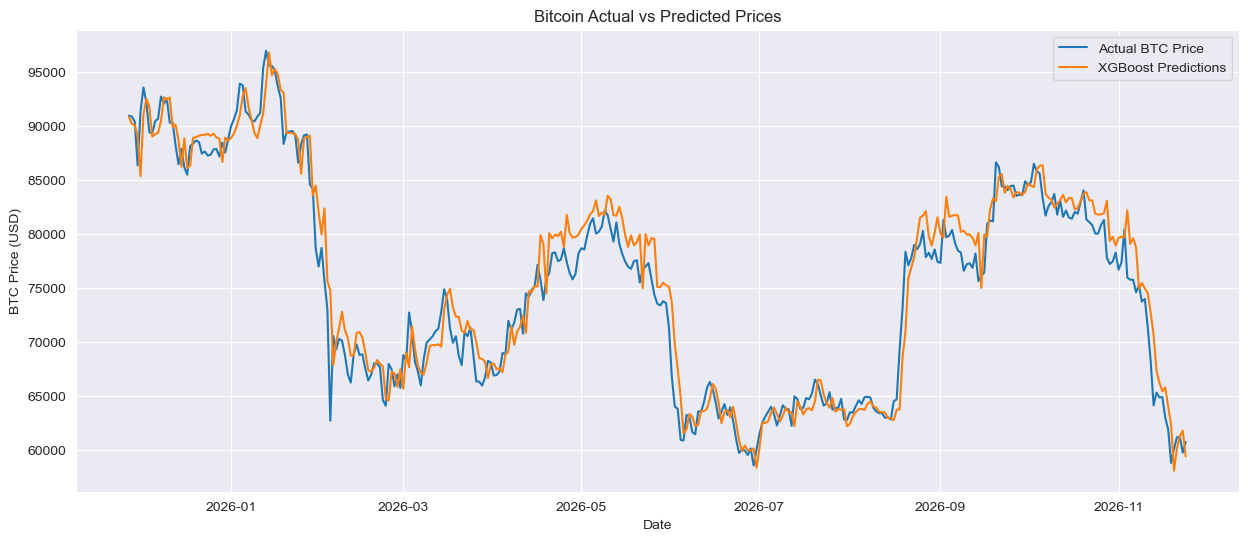

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual BTC Price"
)

plt.plot(
    y_test.index,
    xgb_predictions,
    label="XGBoost Predictions"
)

plt.title("Bitcoin Actual vs Predicted Prices")
plt.xlabel("Date")
plt.ylabel("BTC Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [73]:
prediction_analysis = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": xgb_predictions
})

prediction_analysis["Error"] = (
    prediction_analysis["Actual Price"]
    - prediction_analysis["Predicted Price"]
)

prediction_analysis["Absolute Error"] = (
    prediction_analysis["Error"].abs()
)

display(prediction_analysis.head(10))

print("Average Error:", prediction_analysis["Error"].mean())
print("Maximum Error:", prediction_analysis["Absolute Error"].max())
print("Minimum Error:", prediction_analysis["Absolute Error"].min())

,Actual Price,Predicted Price,Error,Absolute Error
Date,,,,
2025-11-27 00:00:00+00:00,90919.265625,90802.109375,117.156250,117.156250
2025-11-28 00:00:00+00:00,90851.757812,90178.203125,673.554688,673.554688
2025-11-29 00:00:00+00:00,90394.312500,90046.664062,347.648438,347.648438
2025-11-30 00:00:00+00:00,86321.570312,89046.546875,-2724.976562,2724.976562
2025-12-01 00:00:00+00:00,91350.203125,85325.726562,6024.476562,6024.476562
2025-12-02 00:00:00+00:00,93527.804688,91082.039062,2445.765625,2445.765625
2025-12-03 00:00:00+00:00,92141.625000,92471.484375,-329.859375,329.859375
2025-12-04 00:00:00+00:00,89387.757812,91753.570312,-2365.812500,2365.812500
2025-12-05 00:00:00+00:00,89272.375000,88991.171875,281.203125,281.203125


Average Error: -749.3971999827824
Maximum Error: 12059.79296875
Minimum Error: 9.37890625


In [74]:

from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

mape = mean_absolute_percentage_error(
    y_test,
    xgb_predictions
) * 100

mean_error = np.mean(y_test.values - xgb_predictions)

print("XGBoost MAPE:", round(mape, 2), "%")
print("Mean Prediction Error:", round(mean_error, 2))
print("Mean Absolute Error:", round(xgb_mae, 2))

if mean_error > 0:
    print("Model tends to UNDERPREDICT.")
elif mean_error < 0:
    print("Model tends to OVERPREDICT.")
else:
    print("Model has no average prediction bias.")


XGBoost MAPE: 2.31 %
Mean Prediction Error: -749.4
Mean Absolute Error: 1710.9
Model tends to OVERPREDICT.


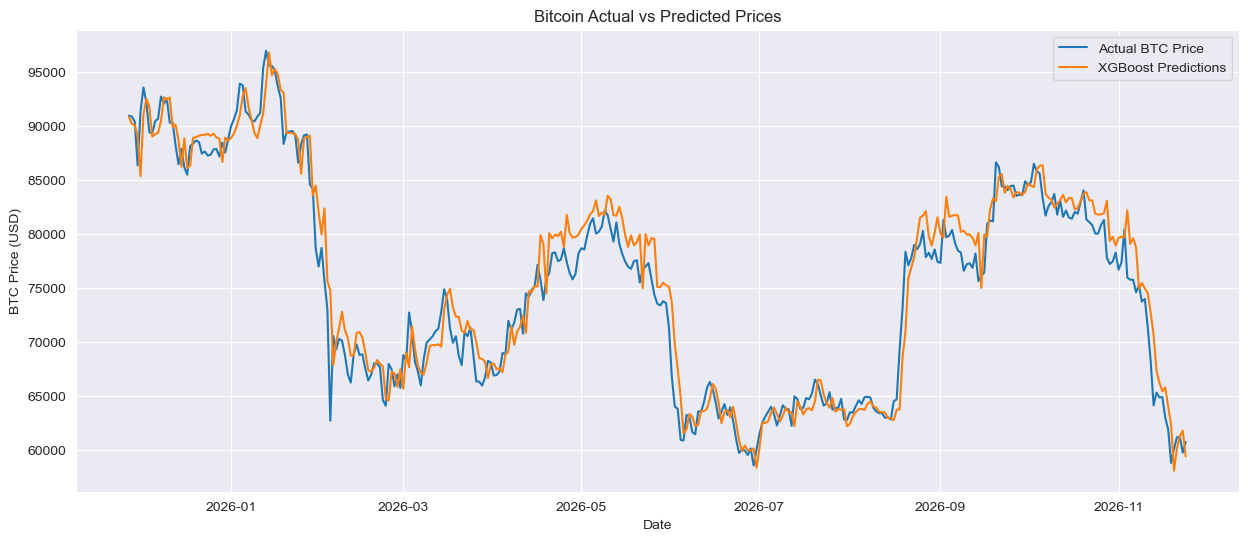

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual BTC Price"
)

plt.plot(
    y_test.index,
    xgb_predictions,
    label="XGBoost Predictions"
)

plt.title("Bitcoin Actual vs Predicted Prices")
plt.xlabel("Date")
plt.ylabel("BTC Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [75]:
import pickle

final_model = {
    "model_name": "Persistence Baseline",
    "feature_name": "BTC_Close_Current",
    "prediction_method": "Tomorrow's price = Today's closing price",
    "mae": float(baseline_mae),
    "rmse": float(baseline_rmse),
    "r2": float(baseline_r2)
}

with open("best_crypto_model.pkl", "wb") as file:
    pickle.dump(final_model, file)

print("Model strategy saved successfully!")

Model strategy saved successfully!


In [76]:
import pickle

with open("best_crypto_model.pkl", "rb") as file:
    model_info = pickle.load(file)

print(model_info)
print(model_info.keys())

{'model_name': 'Persistence Baseline', 'feature_name': 'BTC_Close_Current', 'prediction_method': "Tomorrow's price = Today's closing price", 'mae': 1179.8426893625829, 'rmse': 1711.7950432838168, 'r2': 0.9688152502212443}
dict_keys(['model_name', 'feature_name', 'prediction_method', 'mae', 'rmse', 'r2'])
